# Telugu + English Handwritten Text OCR

Give it an image, get text back. Three engines are included so you can compare:

| Engine | Telugu | English | Handwriting quality | Cost |
|---|---|---|---|---|
| **EasyOCR** (default) | yes | yes | decent on neat writing | free, offline |
| **Tesseract** (optional) | yes (`tel`) | yes | weak on handwriting | free, offline |
| **Claude vision** (optional) | yes | yes | best on messy/cursive Telugu | paid API key |

**Pipeline:** load image -> preprocess (upscale, denoise, contrast) -> OCR -> group into lines -> visualize -> save to `.txt` / `.json`.

Works in Jupyter, VS Code, or Google Colab (a GPU speeds up EasyOCR but is not required).

## 1. Install dependencies

In [1]:
# Run once. Restart the kernel afterwards if imports fail.
# !pip install -q easyocr opencv-python-headless pillow matplotlib numpy anthropic

# OPTIONAL Tesseract engine (Linux/Colab). Uncomment to use:
# !apt-get install -y -q tesseract-ocr tesseract-ocr-tel tesseract-ocr-eng
# !pip install -q pytesseract

# !pip install -q -U langchain-google-genai langchain-core pydantic pillow rapidfuzz openpyxl google-genai

## 2. Configuration and image input

In [2]:
# os.chdir(r'C:\Users\Acer\Desktop\Agentic AI\1. Langchain\Langchain By Krish')
# os.getcwd()

# cd "C:\Users\Acer\Desktop\Agentic AI\1. Langchain\Langchain By Krish"


In [3]:
import os, json, base64, mimetypes
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [4]:


# os.chdir(r'C:\Users\Acer\Desktop\MyProjects\Websites\Proj_Trikuta_OCR')

# # ---------- settings ----------
# IMAGE_PATH = r'C:\Users\Acer\Desktop\MyProjects\Websites\Proj_Trikuta_OCR\sample_img1.jpeg'   
# LANGS = ['te', 'en']             # Telugu + English
# USE_GPU = False                  # True if you have CUDA
# OUTPUT_PREFIX = 'ocr_result'     # outputs: ocr_result.txt / ocr_result.json
# # ------------------------------

# IMG_EXTS = {'.jpg', '.jpeg', '.png', '.webp', '.bmp', '.tif', '.tiff'}

# def resolve_image(path):
#     p = Path(path).expanduser()
#     if p.is_file():
#         return p.resolve()
#     hits = [h for h in Path.cwd().rglob(p.name) if h.is_file()]
#     if hits:
#         print('Found at:', hits[0])
#         return hits[0].resolve()
#     here = [f.name for f in Path.cwd().iterdir() if f.suffix.lower() in IMG_EXTS]
#     raise FileNotFoundError(
#         f"Image '{path}' not found.\n"
#         f"Notebook working directory: {Path.cwd()}\n"
#         f"Image files in that folder: {here or 'none'}\n"
#         f"Fix: set IMAGE_PATH to the full path of your image.")

# def load_image(path):
#     data = np.fromfile(str(path), dtype=np.uint8)      # works with Windows/non-ASCII paths
#     img = cv2.imdecode(data, cv2.IMREAD_COLOR)
#     if img is None:
#         from PIL import Image
#         img = cv2.cvtColor(np.array(Image.open(path).convert('RGB')), cv2.COLOR_RGB2BGR)
#     return img

# IMAGE_PATH = str(resolve_image(IMAGE_PATH))
# img_bgr = load_image(IMAGE_PATH)
# print('Loaded', IMAGE_PATH, 'shape =', img_bgr.shape)
# plt.figure(figsize=(8, 8))
# plt.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
# plt.axis('off'); plt.title('Input image'); plt.show()

In [11]:
import os
from google import genai

client = genai.Client(api_key=os.environ["GOOGLE_API_KEY"])

for m in client.models.list():
    print(m.name)

models/gemini-2.5-flash
models/gemini-2.5-pro
models/gemini-2.5-flash-preview-tts
models/gemini-2.5-pro-preview-tts
models/gemma-4-26b-a4b-it
models/gemma-4-31b-it
models/gemini-flash-latest
models/gemini-flash-lite-latest
models/gemini-pro-latest
models/gemini-2.5-flash-lite
models/gemini-2.5-flash-image
models/gemini-3-flash-preview
models/gemini-3.1-pro-preview
models/gemini-3.1-pro-preview-customtools
models/gemini-3.1-flash-lite-preview
models/gemini-3.1-flash-lite
models/gemini-3-pro-image-preview
models/gemini-3-pro-image
models/nano-banana-pro-preview
models/gemini-3.1-flash-image-preview
models/gemini-3.1-flash-image
models/gemini-3.1-flash-lite-image
models/gemini-nano-banana-2.1
models/gemini-3.5-flash
models/gemini-3.5-flash-lite
models/gemini-omni-flash-preview
models/gemini-omni-1.1-flash
models/gemini-omni-1.2-flash
models/gemini-3.5-transcribe
models/gemini-3.6-flash
models/gemini-3.7-flash
models/gemini-3.8-flash
models/gemini-4-argon
models/lyria-3-clip-preview
models

In [21]:
client.models.list()

In [ ]:
import os, io, re, json, base64, difflib, getpass
from pathlib import Path
from PIL import Image, ImageOps
from IPython.display import display
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.messages import HumanMessage, SystemMessage
from langchain_core.callbacks import UsageMetadataCallbackHandler

if "GOOGLE_API_KEY" not in os.environ:
    os.environ["GOOGLE_API_KEY"] = getpass.getpass("Gemini API key: ")

# See which models your key can use (names change often)
from google import genai
client = genai.Client(api_key=os.environ["GOOGLE_API_KEY"])
available = [m.name.replace("models/", "") for m in client.models.list()]
print([m for m in available if "gemini" in m and "embed" not in m])

# Best first. The first one your key supports gets used. Edit this list if needed.
PREFERRED = ["gemini-3.5-flash-lite","gemini-3.1-flash-lite", "gemini-3.7-flash", "gemini-3.5-flash", "gemini-3.6-flash", "gemini-2.5-pro"]
MODEL_NAME = next((m for m in PREFERRED if m in available), None)
assert MODEL_NAME, "No preferred model available. Set MODEL_NAME manually from the list printed above."
print("Using:", MODEL_NAME)

llm = ChatGoogleGenerativeAI(model=MODEL_NAME, max_retries=3)

['gemini-2.5-flash', 'gemini-2.5-pro', 'gemini-2.5-flash-preview-tts', 'gemini-2.5-pro-preview-tts', 'gemini-flash-latest', 'gemini-flash-lite-latest', 'gemini-pro-latest', 'gemini-2.5-flash-lite', 'gemini-2.5-flash-image', 'gemini-3-flash-preview', 'gemini-3.1-pro-preview', 'gemini-3.1-pro-preview-customtools', 'gemini-3.1-flash-lite-preview', 'gemini-3.1-flash-lite', 'gemini-3-pro-image-preview', 'gemini-3-pro-image', 'gemini-3.1-flash-image-preview', 'gemini-3.1-flash-image', 'gemini-3.1-flash-lite-image', 'gemini-nano-banana-2.1', 'gemini-3.5-flash', 'gemini-3.5-flash-lite', 'gemini-omni-flash-preview', 'gemini-omni-1.1-flash', 'gemini-omni-1.2-flash', 'gemini-3.5-transcribe', 'gemini-3.6-flash', 'gemini-3.7-flash', 'gemini-3.8-flash', 'gemini-4-argon', 'gemini-3.1-flash-tts-preview', 'gemini-3.8-flash-tts', 'gemini-3.8-flash-lite-tts', 'gemini-robotics-er-2-preview', 'gemini-2.5-computer-use-preview-10-2025', 'gemini-3.5-transcribe-live', 'gemini-2.5-flash-native-audio-latest', 'g

In [6]:
# os.listdir()

In [13]:
import openpyxl
from rapidfuzz import process, fuzz

GOTHRAM_XLSX = r"C:\Users\Acer\Desktop\MyProjects\Websites\Proj_Trikuta_OCR\Gothrams-Surname List.xlsx"     # path to your Excel file

def norm(s):
    """Phonetic-ish normalization so spelling variants of the same Telugu name collide."""
    s = re.sub(r"[^A-Z]", "", str(s).upper())
    s = s.replace("W", "V").replace("Z", "J")
    s = re.sub(r"([TDKGBP])H", r"\1", s)          # TH->T, DH->D, KH->K ...
    s = s.replace("EE", "I").replace("OO", "U").replace("AA", "A")
    return re.sub(r"(.)\1+", r"\1", s)            # collapse double letters

class GothramRef:
    def __init__(self, xlsx):
        ws = openpyxl.load_workbook(xlsx, read_only=True).active
        self.gothrams = sorted({str(r[1]).strip().upper()
                                for r in ws.iter_rows(min_row=2, values_only=True) if r and r[1]})
        self._n = [norm(g) for g in self.gothrams]

    def candidates(self, readings, k=12):
        best = {}
        for q in readings:
            nq = norm(q)
            if not nq: continue
            for _, sc, i in process.extract(nq, self._n, scorer=fuzz.ratio, limit=k * 3):
                best[i] = max(best.get(i, 0), sc)
        top = sorted(best.items(), key=lambda x: -x[1])[:k]
        return [(self.gothrams[i], round(sc, 1)) for i, sc in top]

REF = GothramRef(GOTHRAM_XLSX)
print(f"Loaded {len(REF.gothrams)} gothram names")
print(REF.candidates(["Paidibala"], 3))     # sanity check, should list PAIDIBALA / PAIDIPALA variants

Loaded 2100 gothram names
[('PAIDIBAALA', 100.0), ('PAIDIBALA', 100.0), ('PAIDIPAALA', 88.9)]


Loaded: C:\Users\Acer\Desktop\MyProjects\Websites\Proj_Trikuta_OCR\sample_img7.jpeg | size: (1351, 3000)


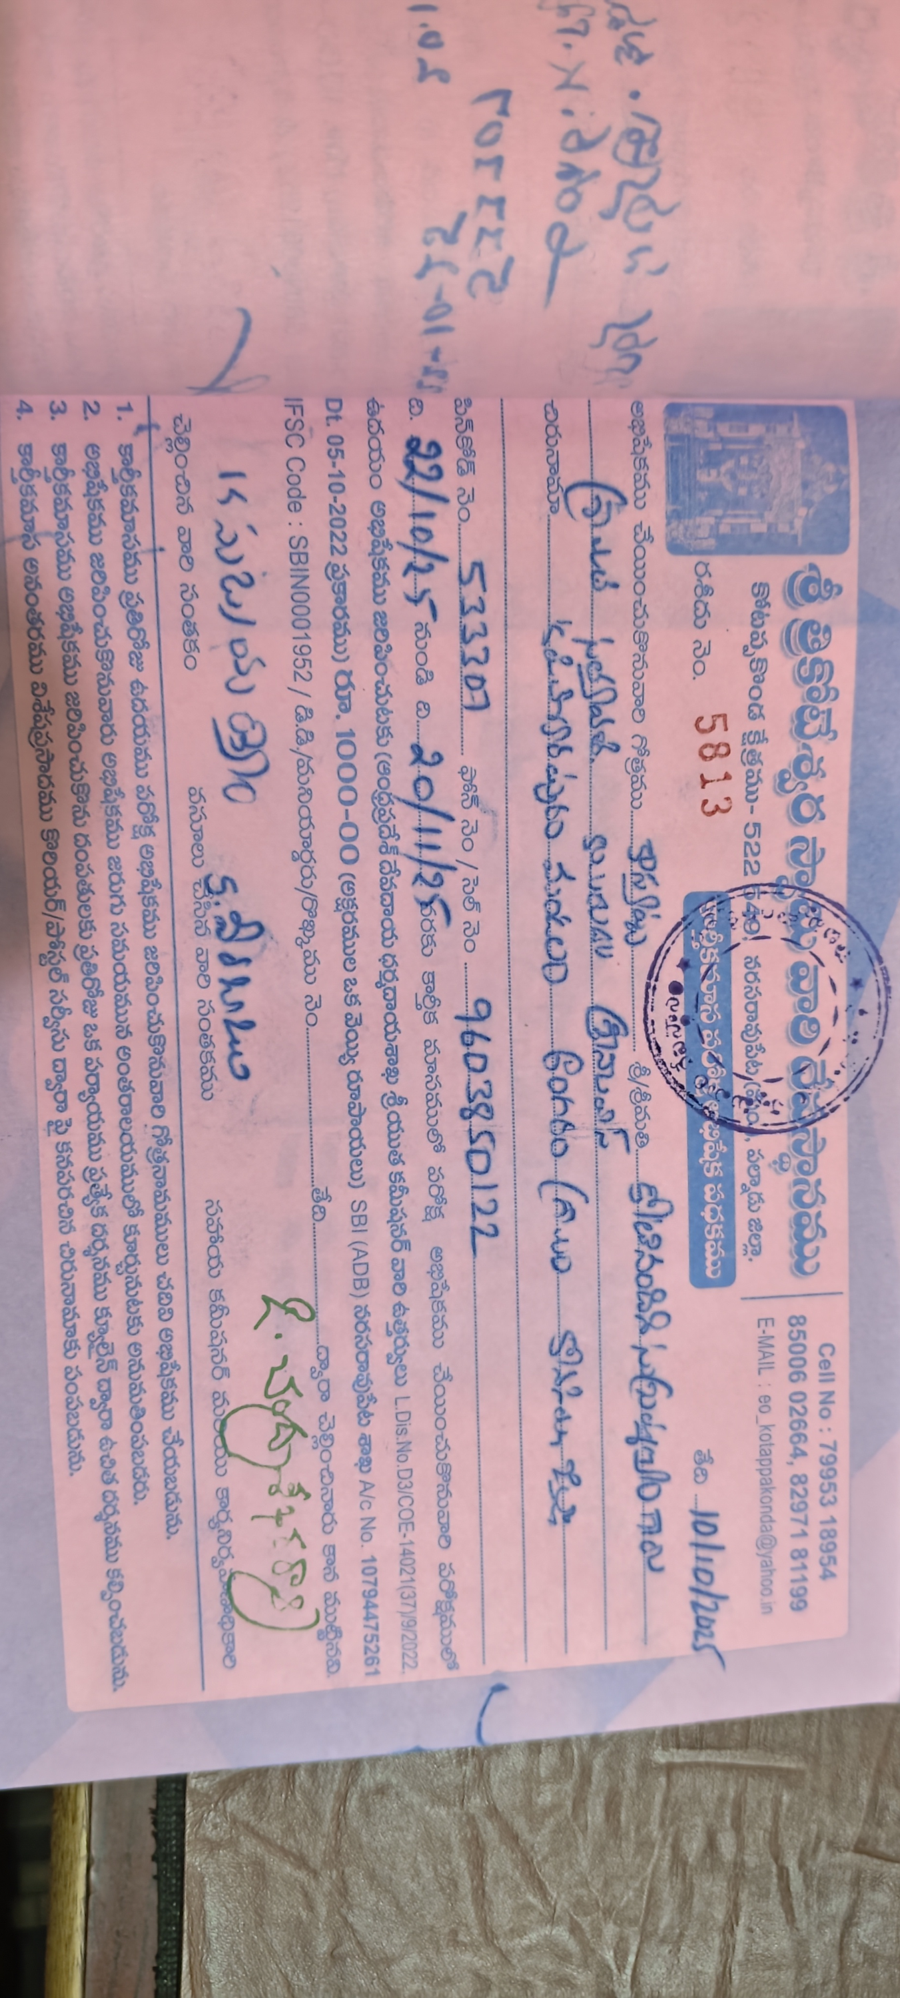

In [14]:
IMAGE_PATH = r"C:\Users\Acer\Desktop\MyProjects\Websites\Proj_Trikuta_OCR\sample_img7.jpeg"    # filename next to the notebook, or a full path like r"C:\Users\you\Pictures\receipt.jpg"

def resolve_image(path):
    p = Path(path).expanduser()
    if p.is_file():
        return p.resolve()
    hits = [h for h in Path.cwd().rglob(p.name) if h.is_file()]
    if hits:
        return hits[0].resolve()
    raise FileNotFoundError(f"Image '{path}' not found. Notebook folder: {Path.cwd()}. Set IMAGE_PATH to the full path.")

def prepare_image(path, max_side=3000):
    img = Image.open(path)
    img = ImageOps.exif_transpose(img).convert("RGB")     # fixes phone-photo rotation
    if max(img.size) > max_side:
        img.thumbnail((max_side, max_side))
    return img

def to_b64(img, q=95):
    buf = io.BytesIO(); img.save(buf, format="JPEG", quality=q)
    return base64.b64encode(buf.getvalue()).decode()

IMAGE_PATH = str(resolve_image(IMAGE_PATH))
pil_img = prepare_image(IMAGE_PATH)
image_b64 = to_b64(pil_img)
print("Loaded:", IMAGE_PATH, "| size:", pil_img.size)
display(pil_img.resize((900, int(pil_img.height * 900 / pil_img.width))))

In [15]:
from pydantic import BaseModel, Field
from typing import List, Optional

SYSTEM = (
    "You are a meticulous OCR engine for Indian documents containing Telugu and English, "
    "both printed and handwritten. Transcribe exactly what is written. Never translate, "
    "transliterate, summarize or invent text. Keep Telugu in Telugu script and English in English."
)

# ---------- data shapes the model must return ----------
class Person(BaseModel):
    given_name: str = Field(description="First/given name exactly as written, e.g. Mahalakshmi")
    surname: str = Field(description="Surname exactly as written, letter by letter. Do not correct it to a 'real' name.")

class HW(BaseModel):
    gothram_readings: List[str] = Field(default_factory=list, description="1-3 plausible spellings of the handwritten GOTHRAM (field after 'గోత్రము'), best first")
    people: List[Person] = Field(default_factory=list, description="Every person listed after the 'శ్రీ/శ్రీమతి' and 'పేరు/చిరునామా' lines, in order")
    address: Optional[str] = Field(None, description="Handwritten address exactly as written, incl. door no. and locality")
    pincode: Optional[str] = Field(None, description="6-digit PIN code")
    phones: List[str] = Field(default_factory=list, description="ALL handwritten phone numbers (one or two). Indian numbers are 10 digits. Digit by digit. NOT the printed temple numbers in the header.")
    uncertain_fields: List[str] = Field(default_factory=list)

class Receipt(HW):
    receipt_no: Optional[str] = None
    date: Optional[str] = Field(None, description="Receipt date as written, e.g. 02/11/26")
    abhishekam_from: Optional[str] = None
    abhishekam_to: Optional[str] = None
    amount_rupees: Optional[str] = None
    temple_name: Optional[str] = None
    handwriting_box_2d: List[int] = Field(default_factory=list,
        description="Bounding box [ymin, xmin, ymax, xmax], normalized 0-1000, tightly around ALL handwritten filled-in lines from the gothram line down to the phone-number line.")

class GothramPick(BaseModel):
    as_written: str = Field(description="Gothram as it appears in the handwriting")
    final: str = Field(description="Final spelling. Use a list spelling ONLY if the handwriting supports it; otherwise as written.")
    matched_in_list: bool
    list_match: Optional[str] = Field(None, description="Exact list entry chosen, if any")
    other_possible_list_matches: List[str] = Field(default_factory=list, description="Up to 3 other list entries that could fit")
    confidence: str = Field(description="high, medium or low")
    reason: str = Field(description="One short sentence")

# ---------- model calls ----------
usage_log = []     # (label, handler) for every Gemini call on the current image

def img_msg(prompt, b64):
    return HumanMessage(content=[{"type": "text", "text": prompt},
                                 {"type": "image", "base64": b64, "mime_type": "image/jpeg"}])

def call_structured(schema, messages, label):
    cb = UsageMetadataCallbackHandler()
    out = llm.with_structured_output(schema).invoke(messages, config={"callbacks": [cb]})
    usage_log.append((label, cb))
    return out.model_dump() if hasattr(out, "model_dump") else out

def full_name(p):
    return f"{p['given_name']} {p['surname']}".strip()

# ---------- cost tracker ----------
# USD per 1M tokens (input, output), prompts <= 200k tokens. Output includes thinking tokens.
PRICING = {
    "gemini-3.1-pro-preview": (2.00, 12.00),
    "gemini-2.5-pro":         (1.25, 10.00),
    "gemini-3-flash-preview": (0.50, 3.00),
    "gemini-3.5-flash":       (1.50, 9.00),
}
USD_TO_INR = 88.0     # set today's rate

def price_for(model):
    for name, p in PRICING.items():
        if model.startswith(name): return p
    return None

def report_usage(handlers, title="Usage for this image"):
    tot_in = tot_out = 0; tot_usd = 0.0; unknown = False
    print(f"\n----- {title} -----")
    for label, cb in handlers:
        for model, u in cb.usage_metadata.items():
            i, o = u.get("input_tokens", 0), u.get("output_tokens", 0)
            reasoning = (u.get("output_token_details") or {}).get("reasoning", 0)
            p = price_for(model)
            if p:
                usd = i / 1e6 * p[0] + o / 1e6 * p[1]; tot_usd += usd
                cost = f"${usd:.4f} (Rs {usd * USD_TO_INR:.2f})"
            else:
                unknown = True; cost = "price unknown, add to PRICING"
            extra = f", of which thinking {reasoning}" if reasoning else ""
            print(f"{label:<28} in {i:,} | out {o:,}{extra} | {cost}")
            tot_in += i; tot_out += o
    print(f"{'TOTAL':<28} in {tot_in:,} | out {tot_out:,} | ${tot_usd:.4f} (Rs {tot_usd * USD_TO_INR:.2f})"
          + ("  [excludes unpriced models]" if unknown else ""))
print("Helpers ready")

Helpers ready


In [16]:
RUN_TRANSCRIPTION = True

usage_log.clear()          # start a fresh cost log for this image
transcription = ""
if RUN_TRANSCRIPTION:
    PROMPT1 = """Transcribe ALL text in this image, top to bottom, line by line.
Rules:
- Keep printed text and handwritten text, in reading order, preserving line breaks.
- Mark handwritten text with [HW: ...] and printed text plainly.
- Copy every number, date, phone number, pincode and receipt number digit by digit.
- If a word is hidden by a stamp, shadow or fold, write [unclear] (give your best guess in parentheses if you have one).
- If a word is illegible, write [illegible]. Do not guess silently."""
    cb = UsageMetadataCallbackHandler()
    resp = llm.invoke([SystemMessage(content=SYSTEM), img_msg(PROMPT1, image_b64)], config={"callbacks": [cb]})
    usage_log.append(("1. Transcription", cb))
    transcription = str(resp.text)
    print(transcription)
    report_usage(usage_log, "After pass 1")

[HW: జేబు : శాంద్రవి 25
నెం. ఎ. రేహంత్
1.05
గొడసర
25-01-05]
శ్రీ త్రికోటేశ్వర స్వామి వారి దేవస్థానము
కోటప్పకొండ క్షేత్రము- 522 549, నరసరావుపేట (మ), పల్నాడు జిల్లా,
రశీదు నెం. [HW: 5813]
[HW: Cell No : 79953 18954
85006 02664, 82971 81199
E-MAIL : eo_kotappakonda@yahoo.in]
అభిషేకము చేయించుకొనువారి గోత్రము [HW: కాశ్యప], శ్రీ/శ్రీమతి [HW: పీటపాటి బ్రహ్మం ప్రసాదు గారు]
[HW: మరియు ఉమాదేవి దంపతులు]
రసుదారు వారు [HW: పిటపాటి రవికుమార్ మండలం గుంటూరు గ్రామము గుంటూరు జిల్లా]
తేది [HW: 10/10/2025]
టిక్కెట్ నెం. [HW: 533207]
ఫిక్స్ నెం / సబ్ నెం [HW: 9603850122]
తే. [HW: 22/10/25] నుండి తే. [HW: 20/11/25] వరకు కార్తీక మాసములో పరోక్ష అభిషేకము చేయించుకొనువారి షరతులతో
ఉదయం అభిషేకము జరిపించుటకు (ఆంధ్రప్రదేశ్ దేవదాయధర్మదాయశాఖ శ్రీ యుత కమీషనర్ వారి ఉత్తర్వులు L. Dis. No. D3/COE-14021(37)/9/2022,
Dt. 05-10-2022 ప్రకారం) రూ. [HW: 1000-00] (అక్షరములు ఒక వేయి రూపాయలు) SBI (ADB) నరసరావుపేట శాఖ A/c No. 10794475261
IFSC Code : SBIN0001952 / డి.డి./మనీఆర్డరు/చెక్కును నెం. .....................తేది .............

In [17]:
P2 = ("Extract the receipt fields. Give 1-3 plausible spellings for the gothram (best first), thinking about how "
      "Telugu gothram names are normally written in English letters. Copy surnames and given names exactly as written. "
      "Look carefully for a second phone number. Use null / empty list when a field is not visible. "
      "Also return handwriting_box_2d around the block of handwritten lines.")

r2 = call_structured(Receipt, [SystemMessage(content=SYSTEM), img_msg(P2, image_b64)], "2. Fields")
print(json.dumps(r2, ensure_ascii=False, indent=2))

{
  "gothram_readings": [
    "కాశ్యప",
    "Kashyapa"
  ],
  "people": [
    {
      "given_name": "శ్రీమతి",
      "surname": "శ్రీవల్లి"
    },
    {
      "given_name": "శ్రీనివాస",
      "surname": "ప్రసాదురావు"
    }
  ],
  "address": "కొటప్పకొండ మండలం నరసరావుపేట",
  "pincode": null,
  "phones": [
    "9603850122"
  ],
  "uncertain_fields": [],
  "receipt_no": "5813",
  "date": "10/10/2022",
  "abhishekam_from": "22/10/22",
  "abhishekam_to": "20/11/22",
  "amount_rupees": "1000-00",
  "temple_name": "శ్రీ త్రికోటేశ్వర స్వామి వారి దేవస్థానము",
  "handwriting_box_2d": [
    220,
    188,
    835,
    968
  ]
}


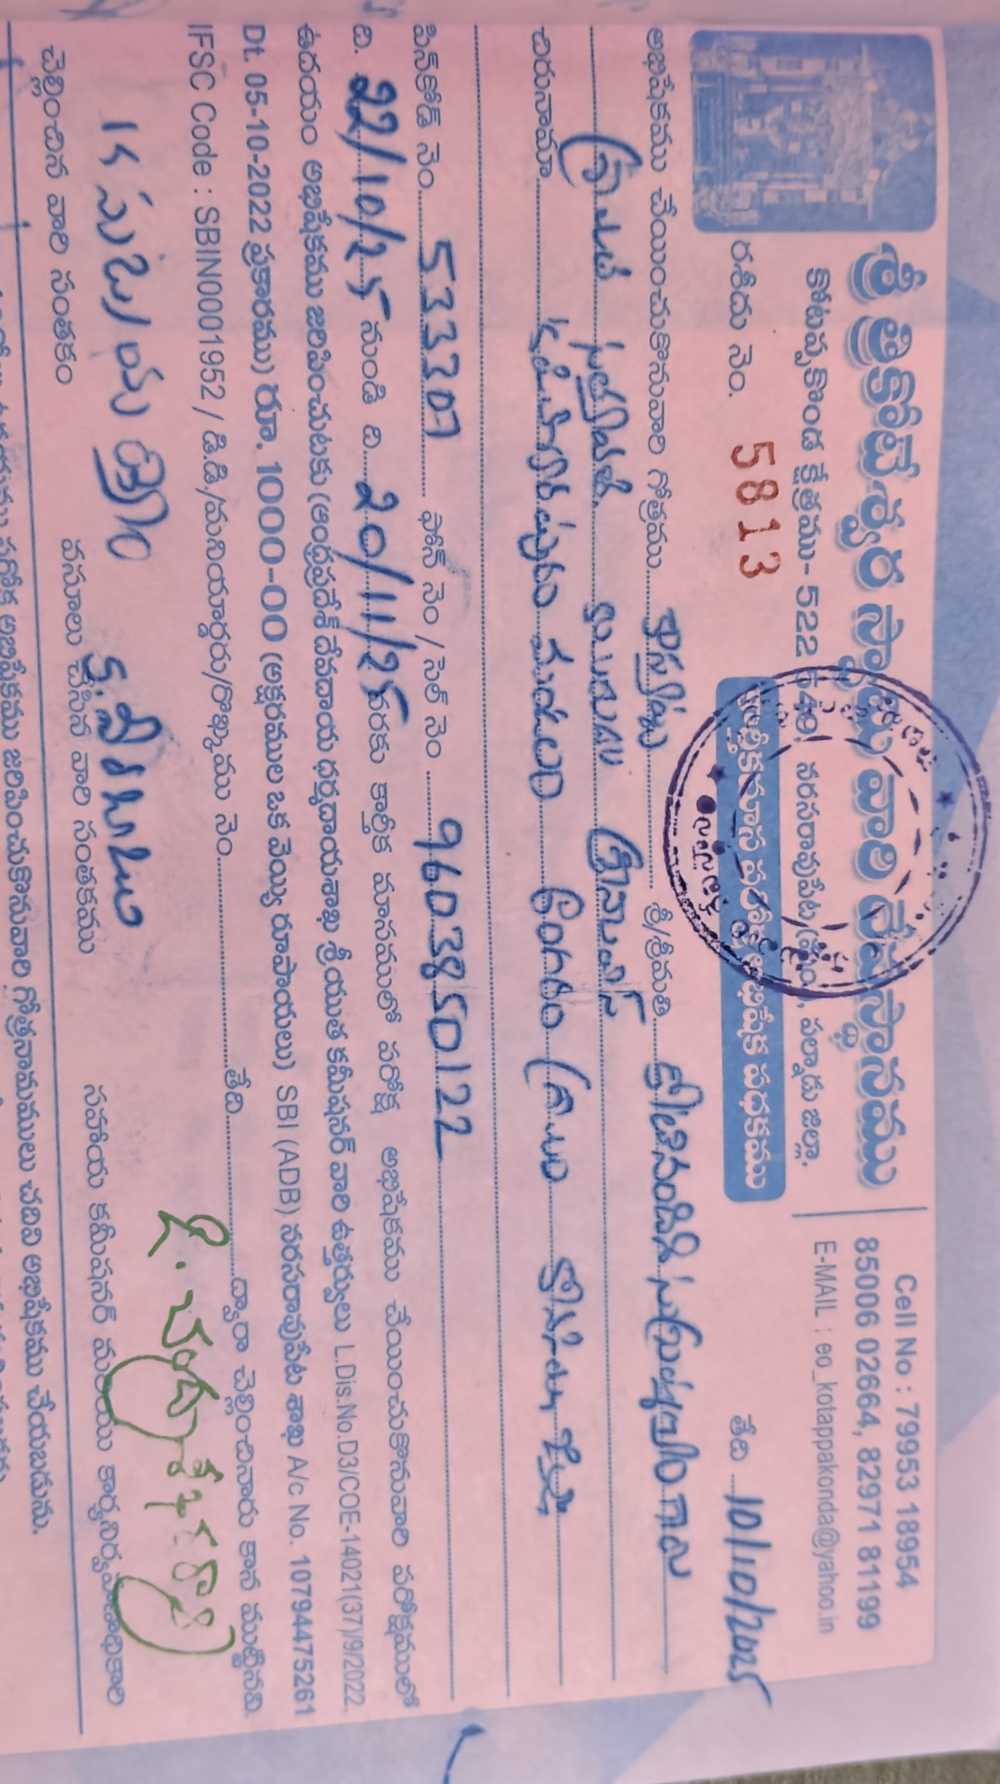

{
  "gothram_readings": [
    "కాశ్యపస",
    "కాశ్యప",
    "కాశ్యపసగో"
  ],
  "people": [
    {
      "given_name": "శ్రీవంశీ",
      "surname": "ప్రసన్నవత్సవాయి"
    }
  ],
  "address": "శ్రీనివాసపురం మండలం, పిండ్రం (గ్రామం, కొప్పర్రు పోస్ట్",
  "pincode": "533307",
  "phones": [
    "9603850122"
  ],
  "uncertain_fields": [
    "address"
  ]
}


In [18]:
def crop_from_box(img, box, pad=0.03):
    try:
        ymin, xmin, ymax, xmax = [float(v) / 1000 for v in box]
        if not (0 <= ymin < ymax <= 1 and 0 <= xmin < xmax <= 1) or (ymax - ymin) * (xmax - xmin) < 0.05:
            return None
        W, H = img.size
        l, t = max(0, xmin - pad) * W, max(0, ymin - pad) * H
        r, b = min(1, xmax + pad) * W, min(1, ymax + pad) * H
        c = img.crop((int(l), int(t), int(r), int(b)))
        if max(c.size) < 2000:                               # upscale so strokes are clearer
            f = 2000 / max(c.size)
            c = c.resize((int(c.width * f), int(c.height * f)), Image.LANCZOS)
        return c
    except Exception:
        return None

crop = crop_from_box(pil_img, r2.get("handwriting_box_2d", []))
if crop is None:
    print("Could not locate the handwritten block; using the full image for this pass.")
    crop, crop_b64 = pil_img, image_b64
else:
    crop_b64 = to_b64(crop)
    w = min(1000, crop.width)
    display(crop.resize((w, int(crop.height * w / crop.width))))     # check that this covers the handwritten lines

P3 = ("This is a zoomed crop of the handwritten filled-in part of a temple receipt. Read ONLY the handwriting: "
      "gothram, each person's given name and surname, address, pincode, and ALL phone numbers. "
      "Give 1-3 plausible spellings for the gothram (best first). Copy surnames exactly as written. "
      "Copy digits one by one. Do not read the printed Telugu.")

r3 = call_structured(HW, [SystemMessage(content=SYSTEM), img_msg(P3, crop_b64)], "3. Zoom re-read")
print(json.dumps(r3, ensure_ascii=False, indent=2))

In [19]:
TOP_K = 40                  # candidates sent in the cheap pass (about 600 tokens)
ESCALATE_BELOW = 85         # if the best fuzzy score is under this, also try the full list

g_readings = list(dict.fromkeys([*r3.get("gothram_readings", []), *r2.get("gothram_readings", [])]))
g_cands = REF.candidates(g_readings, TOP_K)
best_score = g_cands[0][1] if g_cands else 0

RULES = """RULES:
- The reference list is a hint, NOT ground truth. A real gothram may be missing from it or spelled differently.
- Choose a list entry ONLY if each letter is plausible from the handwriting. Prefer the variant that best matches the letters you see.
- If nothing in the list fits, set matched_in_list=false and keep the spelling as written. Never force a match, never invent a name.
- Fill other_possible_list_matches with close alternatives so a human can choose."""

def ask_gothram(full_list):
    sys_msg = SYSTEM
    if full_list:
        sys_msg += ("\n\nREFERENCE - prominent gothram names (spelling variants exist):\n" + ", ".join(REF.gothrams))
    cands = ", ".join(f"{n} ({s:.0f})" for n, s in g_cands) or "none"
    prompt = (f"Look at the handwritten GOTHRAM in the image (the field after 'గోత్రము').\n\n"
              f"Readings from earlier passes: {g_readings}\n"
              f"Closest reference-list entries (similarity out of 100): {cands}\n\n{RULES}")
    label = "4b. Gothram (full list)" if full_list else "4a. Gothram (candidates)"
    return call_structured(GothramPick, [SystemMessage(content=sys_msg), img_msg(prompt, crop_b64)], label)

resolved = ask_gothram(full_list=False)          # cheap pass first

if resolved["confidence"] != "high" or best_score < ESCALATE_BELOW:
    print(f"Escalating to the full list (confidence={resolved['confidence']}, best fuzzy score={best_score})")
    resolved = ask_gothram(full_list=True)

print(json.dumps(resolved, ensure_ascii=False, indent=2))

{
  "as_written": "కాశ్యపస",
  "final": "KASHYAPA",
  "matched_in_list": true,
  "list_match": "KASHYAPA",
  "other_possible_list_matches": [
    "KAASYAPA",
    "KASYAPASA"
  ],
  "confidence": "high",
  "reason": "The handwritten Telugu text clearly says కాశ్యపస which corresponds to Kashyapa with an extra suffix letter sa."
}


In [20]:
def clean_phone(p):
    d = re.sub(r"\D", "", str(p))
    if len(d) == 12 and d.startswith("91"): d = d[2:]       # strip +91
    if len(d) == 11 and d.startswith("0"):  d = d[1:]       # strip leading 0
    return d

def phones_of(r):
    return list(dict.fromkeys(x for x in (clean_phone(p) for p in r.get("phones", [])) if x))

needs_check = []

# --- phones ---
ph2, ph3 = phones_of(r2), phones_of(r3)
phones = ph3 or ph2
if set(ph2) != set(ph3):
    needs_check.append(f"Phone numbers differ between passes: full-image {ph2} vs zoom {ph3}")
for p in phones:
    if not re.fullmatch(r"[6-9]\d{9}", p):
        needs_check.append(f"Phone {p} is not a valid 10-digit Indian mobile")

# --- address ---
addr2, addr3 = (r2.get("address") or ""), (r3.get("address") or "")
address = addr3 or addr2
if addr2 and addr3 and difflib.SequenceMatcher(None, norm(addr2), norm(addr3)).ratio() < 0.85:
    needs_check.append(f"Address differs between passes: '{addr2}' vs '{addr3}'")

# --- pincode ---
pin = re.sub(r"\D", "", r3.get("pincode") or r2.get("pincode") or "")
if not re.fullmatch(r"[1-9]\d{5}", pin):
    needs_check.append(f"Pincode '{pin}' is not a valid 6-digit PIN")
pin2 = re.sub(r"\D", "", r2.get("pincode") or "")
if pin and pin2 and pin2 != pin:
    needs_check.append(f"Pincode differs between passes: {pin2} vs {pin}")

# --- gothram ---
g = resolved
if g["confidence"] != "high" or not g["matched_in_list"]:
    needs_check.append(f"Gothram '{g['final']}' (confidence {g['confidence']}, in list: {g['matched_in_list']}) - {g['reason']}")

# --- names (surnames straight from the text; zoomed read preferred) ---
people2, people3 = r2.get("people", []), r3.get("people", [])
names = [full_name(p) for p in (people3 or people2)]
if sorted(norm(full_name(p)) for p in people2) != sorted(norm(full_name(p)) for p in people3):
    needs_check.append(f"Names differ between passes: {[full_name(p) for p in people2]} vs {[full_name(p) for p in people3]}")

final = {
    "receipt_no": r2.get("receipt_no"), "date": r2.get("date"),
    "gothram": g["final"], "gothram_in_reference_list": g["matched_in_list"],
    "gothram_as_written": g["as_written"], "gothram_alternatives": g["other_possible_list_matches"],
    "names": names, "address": address, "pincode": pin, "phones": phones,
    "abhishekam_from": r2.get("abhishekam_from"), "abhishekam_to": r2.get("abhishekam_to"),
    "amount_rupees": r2.get("amount_rupees"),
    "NEEDS_HUMAN_CHECK": needs_check,
}
print(json.dumps(final, ensure_ascii=False, indent=2))
print("\n>>> FIELDS TO VERIFY BY EYE:" if needs_check else "\n>>> All cross-checks agree.")
for n in needs_check:
    print("  -", n)

report_usage(usage_log, "Total for this image (all passes)")

with open("ocr_gemini.json", "w", encoding="utf-8") as f:
    json.dump({"model": MODEL_NAME, "final": final, "pass1_transcription": transcription,
               "pass2": r2, "pass3_zoom": r3, "pass4_gothram": resolved,
               "usage": {l: cb.usage_metadata for l, cb in usage_log}}, f, ensure_ascii=False, indent=2)
print("\nSaved ocr_gemini.json")

{
  "receipt_no": "5813",
  "date": "10/10/2022",
  "gothram": "KASHYAPA",
  "gothram_in_reference_list": true,
  "gothram_as_written": "కాశ్యపస",
  "gothram_alternatives": [
    "KAASYAPA",
    "KASYAPASA"
  ],
  "names": [
    "శ్రీవంశీ ప్రసన్నవత్సవాయి"
  ],
  "address": "శ్రీనివాసపురం మండలం, పిండ్రం (గ్రామం, కొప్పర్రు పోస్ట్",
  "pincode": "533307",
  "phones": [
    "9603850122"
  ],
  "abhishekam_from": "22/10/22",
  "abhishekam_to": "20/11/22",
  "amount_rupees": "1000-00",
  "NEEDS_HUMAN_CHECK": [
    "Names differ between passes: ['శ్రీమతి శ్రీవల్లి', 'శ్రీనివాస ప్రసాదురావు'] vs ['శ్రీవంశీ ప్రసన్నవత్సవాయి']"
  ]
}

>>> FIELDS TO VERIFY BY EYE:
  - Names differ between passes: ['శ్రీమతి శ్రీవల్లి', 'శ్రీనివాస ప్రసాదురావు'] vs ['శ్రీవంశీ ప్రసన్నవత్సవాయి']

----- Total for this image (all passes) -----
1. Transcription             in 1,249 | out 793 | $0.0090 (Rs 0.79)
2. Fields                    in 1,205 | out 314 | $0.0046 (Rs 0.41)
3. Zoom re-read              in 1,227 | out 1